In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

## Bottomonium
$$ \frac{d^{2}U}{dr^{2}} = \frac{2m}{\hbar^2}\left(V_{eff} - E\right)U$$
$$ g(r) =-\frac{2m}{\hbar^2}\left(V_{eff} - E\right) $$
$$S(r) = 0$$
Hence the Numerov algorithm becomes, 
$$ y_{n+1}\left(1+\frac{h^{2}}{12}g_{n+1}\right)-2y_{n}\left(1+\frac{5h^{2}}{12}g_{n}\right)+y_{n-1}\left(1+\frac{h^{2}}{12}g_{n-1}\right) = 0$$

Where $$V_{eff} = V(r) + \frac{l(l+1)}{r^2} $$
Setting the expression in unit dimensions, $\hbar = 1$ and l = 0. since the ground state energy is being ascertained  $$
V_{eff} = V(r)$$ Therefore    
$$ \frac{d^{2}U}{dr^{2}} = 2m\left(V(r) - E\right)U$$
$$ g(r) =-2m\left(V(r) - E\right) $$
Where the m is the reduced mass of $b\bar{b}$ which is equal to $\frac{m_{b}}{2}$  
$m_{b} = 5.174 GeV/c^2$ so g(r) for $b\bar{b}$ 
$$ g(r) =-2\frac{m_{b}}{2}\left(V(r) - E\right) $$
Power-law Potential, V(r) $= -8.064GeV + (6.898GeV)(r.1GeV)^{0.1}$

where 0.1 is strong coupling constant 



Thus the $U_{n+1}$ is terms of $U_{n}$ and $U_{n-1}$  
$\therefore \left(U_{0}, U_{1}\right)\rightarrow U_{2}\rightarrow U_{3}\rightarrow U_{4} \dots  U_{n}$

## Radial quantum number , n = 1

C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/147781963.py:34: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r, (U/r),  label = 'Eigen energy {} GeV'.format(trial_energy[j]))
C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/147781963.py:34: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r, (U/r),  label = 'Eigen energy {} GeV'.format(trial_energy[j]))
C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/147781963.py:34: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r, (U/r),  label = 'Eigen energy {} GeV'.format(trial_energy[j]))


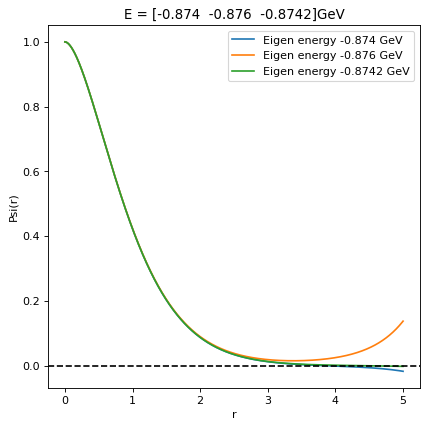

In [3]:
figure(figsize=(6, 6), dpi=80)
#l=0
m_b = 5.174
r_min = 0.0
r_max = 5
h = 0.0001
h_sq = h**2
r = np.arange(r_min, r_max, h)
#centrifugal_term = (l*(l+1))/r**2
U = np.zeros(len(r))
V = np.zeros(len(r))
g_r = np.zeros(len(r))

trial_energy = np.array([-0.874, -0.876, -0.8742])

##trial_energy = float(input('Enter the trial energy: '))

for j in range(len(trial_energy)):
    for i in range(2, len(r)):
        U[0] = 0 
        U[1] = h
        V[0] = (-8.064+(6.898)*(r_min)**0.1)
        V[1] = (-8.064+(6.898)*(r_min + h)**0.1)
        g_r[0] = -2*(m_b/2)*(V[0]-trial_energy[j])
        g_r[1] = -2*(m_b/2)*(V[1]-trial_energy[j])
    
        V[i] =(-8.064+(6.898)*(r[i]**0.1))
        g_r[i] =-2*(m_b/2)*(V[i]-trial_energy[j])  
        U[i] = (2*(1-(5.0/12)*h_sq*g_r[i-1])*U[i-1]-(1+(1.0/12)*h_sq*g_r[i-2])*U[i-2])/(1+(1.0/12)*h_sq*g_r[i])


    
    
    plt.plot(r, (U/r),  label = 'Eigen energy {} GeV'.format(trial_energy[j]))
    
plt.title('E = {}GeV'.format(trial_energy))
plt.axhline(y=0, color='k',linestyle='--')
plt.legend()
plt.xlabel('r')
plt.ylabel('Psi(r)')
plt.savefig('wavebottom.png')
plt.show()


## Normalising the radial wavefunction 
For 3D schrodinger equation problem in a symmetric potential, the normalised reduced radial function is
$$ U(r) = \frac{\phi(r)}{\sqrt{A}}$$ where A is the normalisation integral 

C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/3517487311.py:8: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r, norm_U/r,  label = 'Normalised')


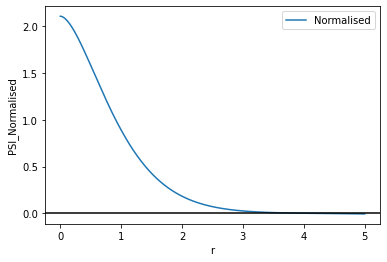

In [4]:
norm_U = np.zeros(len(r))
A = 0
for i in range(0, len(r)):
    A = A + np.abs(U[i])**2*h
for i in range(0, len(r)): 
        norm_U[i] = U[i]/np.sqrt(A)

plt.plot(r, norm_U/r,  label = 'Normalised')
#plt.plot(r, (U/r), label = 'Unnormalised')
plt.axhline(y=0, color='k',linestyle='-')
plt.xlabel('r')
plt.ylabel('PSI_Normalised')
plt.legend() 
plt.show()

##  Radial wavefunction at the origin 
The schrodinger wavefunction at the origin is given by  $$ \psi(0) = \frac{U^{'}(0)}{\sqrt{4\pi}}$$
$$\therefore |\psi(0)|^{2} = \frac{1}{4\pi A}$$
Then, $$ |R(0)|^{2} = \frac{1}{A}$$

In [5]:
R_sq_bb = 1/(A)
print('The radial function at the origin bottomonium is {:.4f} GeV'.format(R_sq_bb))

The radial function at the origin bottomonium is 4.4242 GeV


## Mass of the Bottomonium quark
Using this expression $M_{b\bar b} = 2M_{b} + E_{ns} $ where the $E_{ns}$ is the binding energy which has been calculated above

In [6]:
M_bb = 2 * m_b + trial_energy[2]

print('The mass of the bottomonium is {:.4f} GeV'.format(M_bb))

The mass of the bottomonium is 9.4738 GeV


## Charmonium 

C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/1634581078.py:31: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r_cc, (U_cc/r_cc), label = 'Eigen energy {} GeV'.format(trial_energy_cc[j]))
C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/1634581078.py:31: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r_cc, (U_cc/r_cc), label = 'Eigen energy {} GeV'.format(trial_energy_cc[j]))
C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/1634581078.py:31: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r_cc, (U_cc/r_cc), label = 'Eigen energy {} GeV'.format(trial_energy_cc[j]))


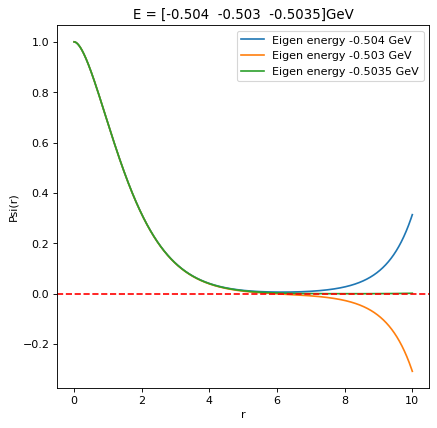

In [7]:
figure(figsize=(6, 6), dpi=80)
m_c = 1.8
r_min_cc = 0
r_max_cc = 10
h_cc = 0.0009
h_sq_cc = h_cc**2
r_cc = np.arange(r_min_cc, r_max_cc, h_cc)
U_cc = np.zeros(len(r_cc))
V_cc = np.zeros(len(r_cc))
g_r_cc = np.zeros(len(r_cc))

trial_energy_cc = np.array([-0.504, -0.503, -0.5035])

##trial_energy = float(input('Enter the trial energy: '))

for j in range(len(trial_energy_cc)):
    for i in range(2, len(r_cc)):
        U_cc[0] = 0 
        U_cc[1] = h_cc
        V_cc[0] = (-8.064+(6.898)*(r_min_cc)**0.1)
        V_cc[1] = (-8.064+(6.898)*(r_min_cc + h_cc)**0.1)
        g_r_cc[0] = -2*(m_c/2)*(V_cc[0]-trial_energy_cc[j])
        g_r_cc[1] = -2*(m_c/2)*(V_cc[1]-trial_energy_cc[j])
    
        V_cc[i] =(-8.064+(6.898)*(r_cc[i]**0.1))
        g_r_cc[i] =-2*(m_c/2)*(V_cc[i]-trial_energy_cc[j])  
        U_cc[i] = (2*(1-(5.0/12)*h_sq_cc*g_r_cc[i-1])*U_cc[i-1]-(1+(1.0/12)*h_sq_cc*g_r_cc[i-2])*U_cc[i-2])/(1+(1.0/12)*h_sq_cc*g_r_cc[i])
        
    
    
    plt.plot(r_cc, (U_cc/r_cc), label = 'Eigen energy {} GeV'.format(trial_energy_cc[j]))
    
plt.title('E = {}GeV'.format(trial_energy_cc))
plt.axhline(y=0, color='r',linestyle='--')
plt.legend()
plt.xlabel('r')
plt.ylabel('Psi(r)')
plt.savefig('wavecharmed.png')
plt.show()

## Normalising the radial wavefunction 
For 3D schrodinger equation problem in a symmetric potential, the normalised reduced radial function is
$$ U(r) = \frac{\phi(r)}{\sqrt{A}}$$ where A is the normalisation integral 



C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/3603638857.py:9: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r_cc, norm_U_cc/r_cc,  label = 'Normalised')


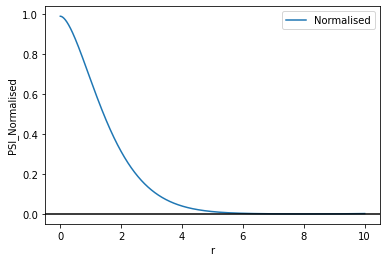

In [8]:
norm_U_cc = np.zeros(len(r_cc))
A_cc = 0
for i in range(0, len(r_cc)):
    A_cc = A_cc + np.abs(U_cc[i])**2*h_cc
for i in range(0, len(r_cc)): 
        norm_U_cc[i] = U_cc[i]/np.sqrt(A_cc)


plt.plot(r_cc, norm_U_cc/r_cc,  label = 'Normalised')
#plt.plot(r, (U/r), label = 'Unnormalised')
plt.axhline(y=0, color='k',linestyle='-')
plt.xlabel('r')
plt.ylabel('PSI_Normalised')
plt.legend()
plt.savefig('wavepowercharmonium.png')
plt.show()

##  Radial wavefunction at the origin 
The schrodinger wavefunction at the origin is given by  $$ \psi(0) = \frac{U^{'}(0)}{\sqrt{4\pi}}$$
$$\therefore |\psi(0)|^{2} = \frac{1}{4\pi A}$$
Then, $$ |R(0)|^{2} = \frac{1}{A}$$

In [9]:
R_sq_cc = 1/(A_cc)
print('The radial function at the origin for charmonium is {:.4f} GeV'.format(R_sq_cc))

The radial function at the origin for charmonium is 0.9785 GeV


## Mass of the charmonium quark
Using this expression $M_{c\bar c} = 2M_{c} + E_{ns} $ where the $E_{ns}$ is the binding energy which has been calculated above

In [10]:
M_cc = 2 * m_c + trial_energy_cc[2]

print('The mass of the charmonium is {:.4f} GeV'.format(M_cc))

The mass of the charmonium is 3.0965 GeV


## Spin Average 
Spin average(1S) = $$\frac{3M_{J/\psi}+M_{\eta_{c}}}{4}$$ 




## VECTOR - PSEUDOVECTOR MASS DIFFERENCE  

In [11]:
def splitting(strong_constant, wavefunction_sq, mass_i,mass_j):
    final = (32*np.pi*strong_constant*wavefunction_sq)/(4*np.pi*9*mass_i*mass_j)
    return final
alpha_s = 0.43

charmonium_splitting = splitting(alpha_s, R_sq_cc, m_c,m_c)
bottomonium_splitting = splitting(alpha_s, R_sq_bb, m_b,m_b)

print(charmonium_splitting)
print(bottomonium_splitting)

    

0.11542976787580235
0.06316775640637363


## c$\bar{b}$

Enter the trial energy: -0.644


C:\Users\oppon\AppData\Local\Temp/ipykernel_9608/2075173540.py:30: RuntimeWarning: invalid value encountered in true_divide
  plt.plot(r_cb, (U_cb/r_cb))


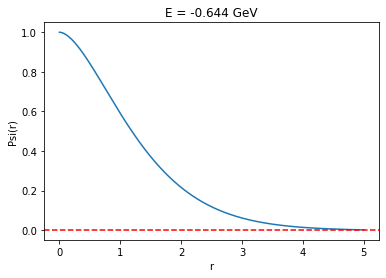

In [18]:
## in terms of GeV
m_c = 1.8
m_b = 5.174
m_cb = (m_b*m_c)/(m_b+m_c)
r_min_cb = 0
r_max_cb = 5
h_cb = 0.0009
h_sq_cb = h_cb**2
r_cb = np.arange(r_min_cb, r_max_cb, h_cb)
U_cb = np.zeros(len(r_cb))
V_cb = np.zeros(len(r_cb))
g_r_cb = np.zeros(len(r_cb))

trial_energy_cb = float(input('Enter the trial energy: '))

for i in range(2, len(r_cb)):
    
    U_cb[0] = 0 
    U_cb[1] = h_cb
    V_cb[0] = (-8.064+(6.898)*(r_min_cb**0.1))
    V_cb[1] = (-8.064+(6.898)*((r_min_cb+h_cb)**0.1))
    g_r_cb[0] = -2*(m_cb)*(V_cb[0]-trial_energy_cb)
    g_r_cb[1] = -2*(m_cb)*(V_cb[1]-trial_energy_cb)
    
    V_cb[i] = (-8.064+(6.898)*(r_cb[i]**0.1))
    g_r_cb[i] =-2*(m_cb)*(V_cb[i]-trial_energy_cb)  
    U_cb[i] = (2*(1-(5.0/12)*h_sq_cb*g_r_cb[i-1])*U_cb[i-1]-(1+(1.0/12)*h_sq_cb*g_r_cb[i-2])*U_cb[i-2])/(1+(1.0/12)*h_sq_cb*g_r_cb[i])


plt.plot(r_cb, (U_cb/r_cb))
plt.title('E = {} GeV'.format(trial_energy_cb))
plt.axhline(y=0, color='r',linestyle='--')
#plt.yscale('log')
plt.xlabel('r')
plt.ylabel('Psi(r)')
plt.savefig('wavelogcharmcb.png')
plt.show()



## Using the simpsons integration tallies with the the above for loop

In [31]:
import numpy as np
from scipy import integrate

def normalise_psi(psi,r):
    psi_sq = integrate.simps(abs(psi)**2, r)
    return psi/np.sqrt(psi_sq)
Norm_U = normalise_psi(U,r)